# Анализ пользовательского поведения интернет-магазина

**Вопрос:** на каких этапах пользователи переходят от просмотра товара к покупке и как часто возвращаются на сайт?

Это учебный анализ на открытых данных Retail Rocket. Если оригинальный файл пока не скачан, ноутбук использует демонстрационную искусственную выборку. В таком случае цифры ниже нужны только для проверки кода.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW_FILE = ROOT / "data" / "raw" / "events.csv"
DEMO_FILE = ROOT / "data" / "demo" / "events_demo.csv"
OUT_FIG = ROOT / "reports" / "figures"
OUT_TAB = ROOT / "reports" / "tables"
OUT_FIG.mkdir(parents=True, exist_ok=True)
OUT_TAB.mkdir(parents=True, exist_ok=True)

if RAW_FILE.exists():
    file_path = RAW_FILE
    data_type = "оригинальный Retail Rocket"
else:
    file_path = DEMO_FILE
    data_type = "ДЕМО: искусственная выборка, не оригинальный Retail Rocket"

print(f"Источник: {data_type}")
events = pd.read_csv(file_path)
events.head()

Источник: ДЕМО: искусственная выборка, не оригинальный Retail Rocket


,timestamp,visitorid,event,itemid,transactionid
0,1430644937000,100050,view,1170,NaN
1,1430647397000,100050,view,1156,NaN
2,1430648237000,100050,view,1101,NaN
3,1430649257000,100050,view,1062,NaN
4,1430650757000,100050,view,1035,NaN


## 1. Первичная проверка данных

Сначала посмотрю на размер таблицы, типы событий, пропуски и период наблюдений. Пустой `transactionid` у просмотров и добавлений в корзину — ожидаемая ситуация.

In [2]:
print("Размер таблицы:", events.shape)
display(events.info())
display(events.isna().sum().to_frame("missing_values"))
display(events["event"].value_counts().rename_axis("event").to_frame("events"))

Размер таблицы: (4280, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4280 entries, 0 to 4279
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   timestamp      4280 non-null   int64  
 1   visitorid      4280 non-null   int64  
 2   event          4280 non-null   object 
 3   itemid         4280 non-null   int64  
 4   transactionid  83 non-null     float64
dtypes: float64(1), int64(3), object(1)
memory usage: 167.3+ KB


None

,missing_values
timestamp,0
visitorid,0
event,0
itemid,0
transactionid,4197


,events
event,
view,3957
addtocart,240
transaction,83


In [3]:
# Перевожу timestamp из миллисекунд Unix в datetime UTC
events["event_time"] = pd.to_datetime(events["timestamp"], unit="ms", utc=True)
print("Период:", events["event_time"].min(), "—", events["event_time"].max())
print("Уникальных посетителей:", events["visitorid"].nunique())
print("Уникальных товаров:", events["itemid"].nunique())
print("Полных дублей:", events.duplicated().sum())

Период: 2015-05-03 09:22:17+00:00 — 2015-10-07 00:27:17+00:00
Уникальных посетителей: 850
Уникальных товаров: 250
Полных дублей: 0


## 2. Какие события встречаются чаще

По распределению событий можно понять общий состав данных. Но большое число просмотров само по себе не означает хорошую конверсию — для этого отдельно посмотрю на переходы между шагами.

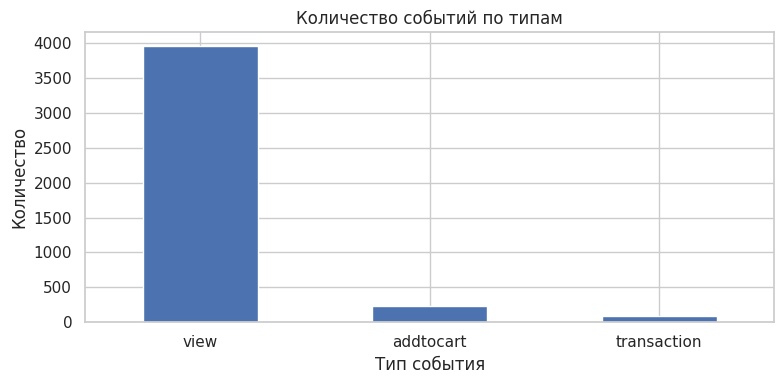

In [4]:
event_counts = events["event"].value_counts().reindex(["view", "addtocart", "transaction"]).fillna(0)
ax = event_counts.plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_title("Количество событий по типам")
ax.set_xlabel("Тип события")
ax.set_ylabel("Количество")
plt.tight_layout()
plt.savefig(OUT_FIG / "event_types.png", dpi=150)
plt.show()

## 3. Упрощённая воронка на уровне посетителя

Для каждого посетителя беру первое событие `view`, затем первое добавление в корзину после этого просмотра и первую покупку после добавления в корзину. Это не сессионная воронка: события могут происходить в разные дни, а товар на разных шагах может отличаться.

In [5]:
views = (events.loc[events.event == "view"]
         .groupby("visitorid")["timestamp"].min()
         .rename("first_view"))

cart_events = events.loc[events.event == "addtocart", ["visitorid", "timestamp"]].merge(
    views, on="visitorid", how="inner"
)
cart_events = cart_events[cart_events.timestamp >= cart_events.first_view]
carts = cart_events.groupby("visitorid")["timestamp"].min().rename("first_cart")

purchase_events = events.loc[events.event == "transaction", ["visitorid", "timestamp"]].merge(
    carts, on="visitorid", how="inner"
)
purchase_events = purchase_events[purchase_events.timestamp >= purchase_events.first_cart]
purchases = purchase_events.groupby("visitorid")["timestamp"].min().rename("first_purchase")

funnel = views.to_frame().join(carts, how="left").join(purchases, how="left")
summary = pd.Series({
    "view": funnel.index.nunique(),
    "add_to_cart": funnel["first_cart"].notna().sum(),
    "purchase": funnel["first_purchase"].notna().sum()
}, name="users").to_frame()
summary["conversion_from_previous_step_pct"] = [
    100,
    summary.loc["add_to_cart", "users"] / summary.loc["view", "users"] * 100,
    summary.loc["purchase", "users"] / summary.loc["add_to_cart", "users"] * 100 if summary.loc["add_to_cart", "users"] else np.nan
]
summary["conversion_from_view_pct"] = summary["users"] / summary.loc["view", "users"] * 100
summary

,users,conversion_from_previous_step_pct,conversion_from_view_pct
view,850,100.000000,100.000000
add_to_cart,240,28.235294,28.235294
purchase,83,34.583333,9.764706


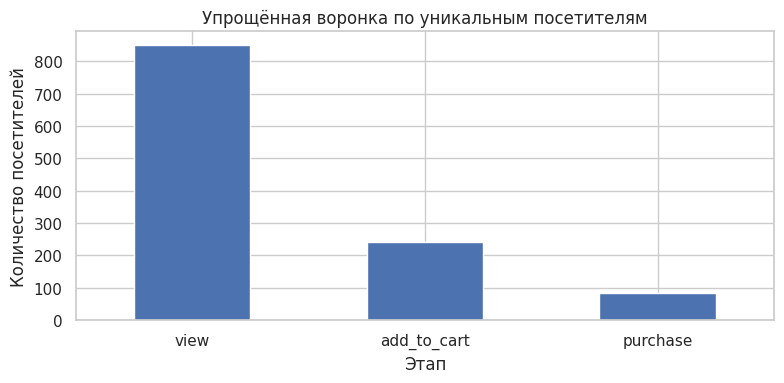

In [6]:
ax = summary["users"].plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_title("Упрощённая воронка по уникальным посетителям")
ax.set_xlabel("Этап")
ax.set_ylabel("Количество посетителей")
plt.tight_layout()
plt.savefig(OUT_FIG / "visitor_funnel.png", dpi=150)
plt.show()
summary.to_csv(OUT_TAB / "visitor_funnel.csv")

## 4. Недельное удержание

Когорта — неделя первого события пользователя. Активным считаю пользователя, у которого было хотя бы одно событие в соответствующую неделю. Это недельный retention, а не классические D1/D7.

In [7]:
weekly = events[["visitorid", "event_time"]].copy()
weekly["activity_week"] = weekly["event_time"].dt.to_period("W").dt.start_time
user_weeks = weekly[["visitorid", "activity_week"]].drop_duplicates()
cohort = user_weeks.groupby("visitorid")["activity_week"].min().rename("cohort_week")
user_weeks = user_weeks.join(cohort, on="visitorid")
user_weeks["week_number"] = ((user_weeks["activity_week"] - user_weeks["cohort_week"]).dt.days // 7).astype(int)
cohort_sizes = cohort.groupby(cohort).size().rename("cohort_users")
cohort_data = (user_weeks.groupby(["cohort_week", "week_number"])["visitorid"]
               .nunique().rename("active_users").reset_index())
cohort_data = cohort_data.join(cohort_sizes, on="cohort_week")
cohort_data["retention"] = cohort_data["active_users"] / cohort_data["cohort_users"]
retention_pivot = cohort_data.pivot(index="cohort_week", columns="week_number", values="retention")
retention_pivot.iloc[:, :8].style.format("{:.1%}").background_gradient(cmap="Blues")

/tmp/ipykernel_1169/1448955419.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  weekly["activity_week"] = weekly["event_time"].dt.to_period("W").dt.start_time


week_number,0,1,2,3,4,5,6,7
cohort_week,,,,,,,,
2015-04-27 00:00:00,100.0%,16.7%,16.7%,nan%,nan%,nan%,nan%,nan%
2015-05-04 00:00:00,100.0%,2.3%,9.3%,4.7%,9.3%,2.3%,7.0%,nan%
2015-05-11 00:00:00,100.0%,6.1%,4.1%,4.1%,4.1%,6.1%,10.2%,nan%
2015-05-18 00:00:00,100.0%,6.8%,5.1%,5.1%,10.2%,nan%,nan%,nan%
2015-05-25 00:00:00,100.0%,6.0%,2.0%,4.0%,4.0%,6.0%,nan%,nan%
2015-06-01 00:00:00,100.0%,2.0%,nan%,nan%,6.0%,6.0%,6.0%,2.0%
2015-06-08 00:00:00,100.0%,nan%,3.4%,6.8%,1.7%,3.4%,3.4%,nan%
2015-06-15 00:00:00,100.0%,2.0%,2.0%,7.8%,2.0%,3.9%,nan%,nan%
2015-06-22 00:00:00,100.0%,8.2%,10.2%,8.2%,nan%,4.1%,nan%,nan%


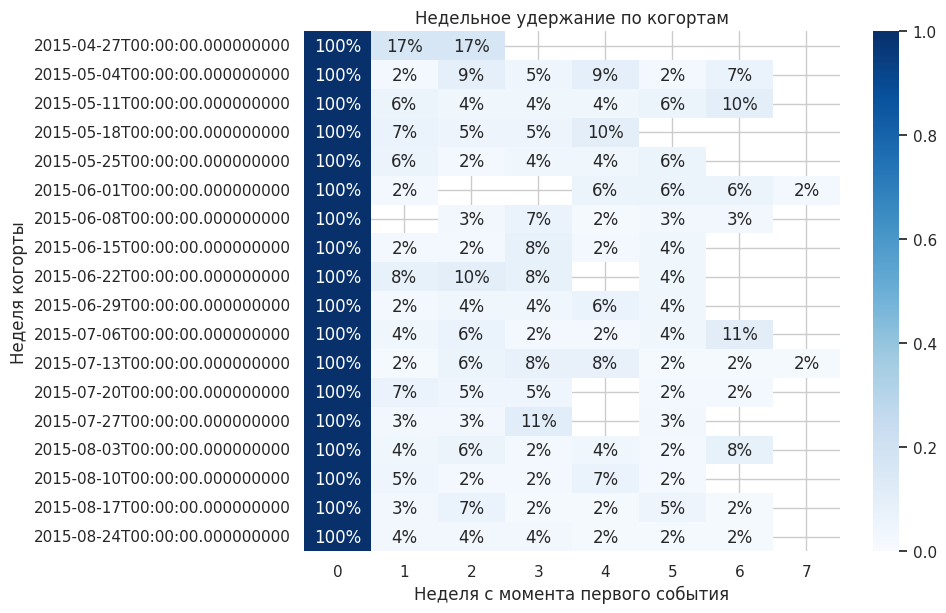

In [8]:
plt.figure(figsize=(10, max(4, len(retention_pivot) * 0.35)))
sns.heatmap(retention_pivot.iloc[:, :8], annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1)
plt.title("Недельное удержание по когортам")
plt.xlabel("Неделя с момента первого события")
plt.ylabel("Неделя когорты")
plt.tight_layout()
plt.savefig(OUT_FIG / "weekly_retention.png", dpi=150)
plt.show()
retention_pivot.to_csv(OUT_TAB / "weekly_retention.csv")

## 5. Популярные товары

Посмотрю на товары с наибольшим количеством событий `transaction`. Важно: это число событий покупки, а не выручка и не количество оплаченных заказов в денежном выражении.

In [9]:
top_items = (events.groupby("itemid")
             .agg(views=("event", lambda x: (x == "view").sum()),
                  cart_adds=("event", lambda x: (x == "addtocart").sum()),
                  purchase_events=("event", lambda x: (x == "transaction").sum()),
                  visitors=("visitorid", "nunique"))
             .sort_values(["purchase_events", "views"], ascending=False)
             .head(15))
top_items

,views,cart_adds,purchase_events,visitors
itemid,,,,
1103,16,3,3,15
1238,16,3,3,16
1194,24,2,2,23
1218,21,4,2,21
1126,20,3,2,20
1233,18,2,2,18
1094,16,2,2,16
1097,16,2,2,16
1170,16,2,2,16


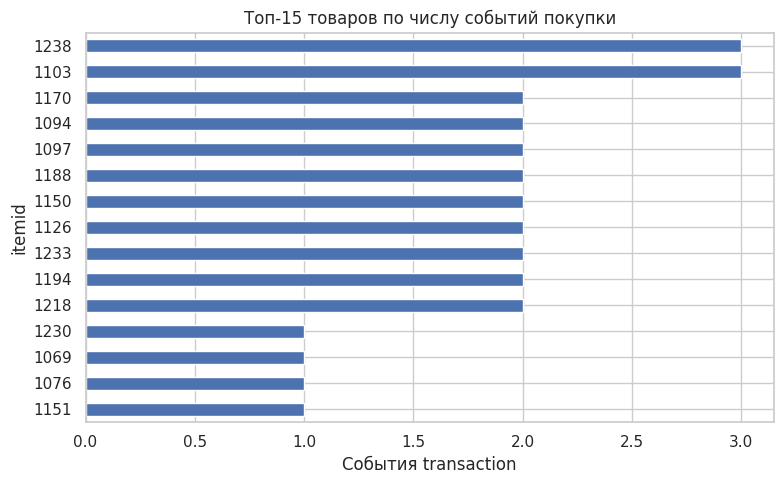

In [10]:
ax = top_items["purchase_events"].sort_values().plot(kind="barh", figsize=(8, 5))
ax.set_title("Топ-15 товаров по числу событий покупки")
ax.set_xlabel("События transaction")
ax.set_ylabel("itemid")
plt.tight_layout()
plt.savefig(OUT_FIG / "top_items.png", dpi=150)
plt.show()
top_items.to_csv(OUT_TAB / "top_items.csv")

## 6. Выводы и ограничения

Перед тем как сделать выводы, проверьте строку `Источник` в начале ноутбука. Если там указано `ДЕМО`, численные результаты относятся только к искусственной выборке и не должны использоваться как результаты анализа Retail Rocket.

При работе с оригинальными данными я бы зафиксировал:

- конверсию между этапами упрощённой пользовательской воронки;
- когорты с более высоким/низким недельным retention;
- товары с высокой частотой просмотров и покупок;
- ограничения: отсутствие цены и сессионной разметки.

**Следующий шаг:** пересчитать воронку на уровне сессий и проверить, сохраняются ли выводы при другом определении сессии.